<a href="https://colab.research.google.com/github/Judame21/BlackJack-Game-IA-Generated/blob/main/IDS_0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
##  IMPORTACIÓN DE LIBRERÍAS Y CARGA DE DATOS
## Data set importado de Kaggle
## Nombre data Set UNSW_NB15: Ciberseguridad

import os
import seaborn as sns
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

path = kagglehub.dataset_download("mrwellsdavid/unsw-nb15")

## Se guarda variable en df
df=pd.read_csv(path+"/UNSW_NB15_training-set.csv")
df = df.drop(columns="id")

Using Colab cache for faster access to the 'unsw-nb15' dataset.


# Analisis del dataset


In [29]:
print("--- DIMENSIONES DEL DATASET ---")
print(f"Filas: {df.shape[0]}, Columnas: {df.shape[1]}\n")


--- DIMENSIONES DEL DATASET ---
Filas: 82332, Columnas: 44



In [30]:
print("--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---")
print(df.info())

--- INFORMACIÓN GENERAL Y TIPOS DE DATOS ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 82332 entries, 0 to 82331
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   dur                82332 non-null  float64
 1   proto              82332 non-null  object 
 2   service            82332 non-null  object 
 3   state              82332 non-null  object 
 4   spkts              82332 non-null  int64  
 5   dpkts              82332 non-null  int64  
 6   sbytes             82332 non-null  int64  
 7   dbytes             82332 non-null  int64  
 8   rate               82332 non-null  float64
 9   sttl               82332 non-null  int64  
 10  dttl               82332 non-null  int64  
 11  sload              82332 non-null  float64
 12  dload              82332 non-null  float64
 13  sloss              82332 non-null  int64  
 14  dloss              82332 non-null  int64  
 15  sinpkt             82332 

In [31]:
print("--- DATOS ESTADISTICOS ---")
print(df.describe())

--- DATOS ESTADISTICOS ---
                dur         spkts         dpkts        sbytes        dbytes  \
count  82332.000000  82332.000000  82332.000000  8.233200e+04  8.233200e+04   
mean       1.006756     18.666472     17.545936  7.993908e+03  1.323379e+04   
std        4.710444    133.916353    115.574086  1.716423e+05  1.514715e+05   
min        0.000000      1.000000      0.000000  2.400000e+01  0.000000e+00   
25%        0.000008      2.000000      0.000000  1.140000e+02  0.000000e+00   
50%        0.014138      6.000000      2.000000  5.340000e+02  1.780000e+02   
75%        0.719360     12.000000     10.000000  1.280000e+03  9.560000e+02   
max       59.999989  10646.000000  11018.000000  1.435577e+07  1.465753e+07   

               rate          sttl          dttl         sload         dload  \
count  8.233200e+04  82332.000000  82332.000000  8.233200e+04  8.233200e+04   
mean   8.241089e+04    180.967667     95.713003  6.454902e+07  6.305470e+05   
std    1.486204e+05    1

In [32]:
print("\n--- PRIMERAS 5 FILAS ---")
df.head()


--- PRIMERAS 5 FILAS ---


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,...,1,2,0,0,0,1,2,0,Normal,0
1,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,...,1,2,0,0,0,1,2,0,Normal,0
2,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,...,1,3,0,0,0,1,3,0,Normal,0
3,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,...,1,3,0,0,0,2,3,0,Normal,0
4,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,...,1,3,0,0,0,2,3,0,Normal,0


# Nulos Y Duplicados


In [33]:
print("\n--- VALORES NULOS POR COLUMNA ---")
nulos = df.isna().sum()
porcentaje_nulos = (df.isna().sum() / len(df)) * 100
tabla_nulos = pd.DataFrame(
    {"Nulos": nulos, "Porcentaje (%)": porcentaje_nulos}
)
print(tabla_nulos[tabla_nulos["Nulos"] > 0])

# Buscamos duplicados en todo el DataFrame
duplicados = df.duplicated()

# Filtramos el DataFrame usando la máscara booleana
dfrepetidos = df[duplicados]
repetidos_normal = dfrepetidos["attack_cat"] == "Normal"
repetidos_ataque = dfrepetidos["attack_cat"] != "Normal"

print(f"\nCantidad de filas duplicadas encontradas: {len(dfrepetidos)}")
display(dfrepetidos.sort_values("dur").head())

###En nuestro caso no se encuentran datos nulos y los casos duplicados son validos

print("REPETIDOS == ATAQUES: " + str(repetidos_ataque.sum()))
print("REPETIDOS == NORMAL: " + str(repetidos_normal.sum()))



--- VALORES NULOS POR COLUMNA ---
Empty DataFrame
Columns: [Nulos, Porcentaje (%)]
Index: []

Cantidad de filas duplicadas encontradas: 26387


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
81043,0.0,arp,-,INT,1,0,46,0,0.0,0,...,1,1,0,0,0,1,1,1,Normal,0
81847,0.0,arp,-,INT,1,0,46,0,0.0,0,...,1,1,0,0,0,1,1,1,Normal,0
81339,0.0,arp,-,INT,1,0,46,0,0.0,0,...,1,1,0,0,0,1,1,1,Normal,0
81395,0.0,arp,-,INT,1,0,46,0,0.0,0,...,1,1,0,0,0,1,1,1,Normal,0
81396,0.0,arp,-,INT,1,0,46,0,0.0,0,...,1,1,0,0,0,1,1,1,Normal,0


REPETIDOS == ATAQUES: 23593
REPETIDOS == NORMAL: 2794


# Analisis Univariado

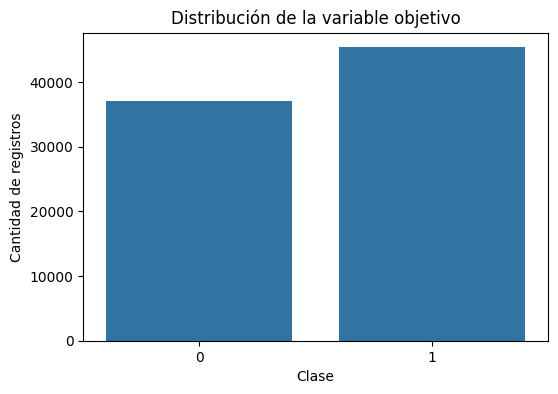

In [34]:
## Para nuestro data set las variables candidatas para un analisis univariado serían: label, attack_cat, proto, service

plt.figure(figsize=(6, 4))

sns.countplot(x="label", data=df)

plt.title("Distribución de la variable objetivo")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")

plt.show()

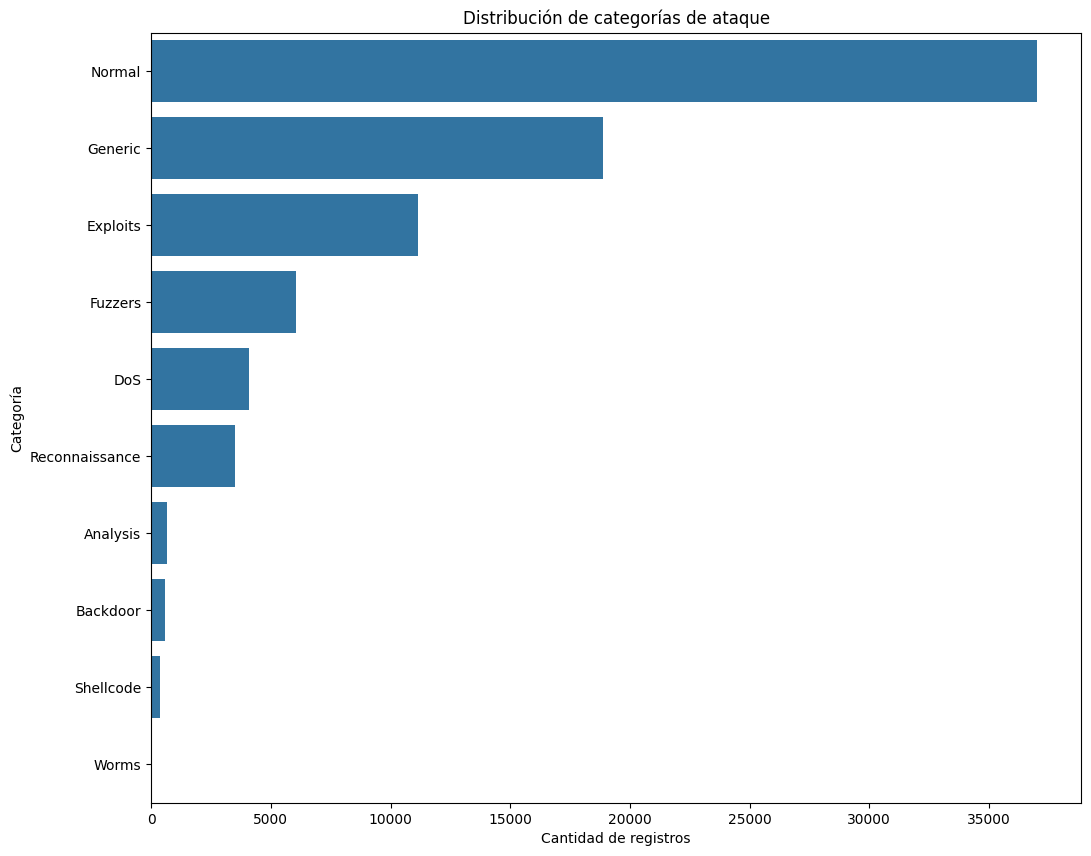

In [35]:
## Analisis univariado categoría attack_cat

plt.figure(figsize=(12, 10))

sns.countplot(
    y="attack_cat",
    data=df,
    order=df["attack_cat"].value_counts().index
)

plt.title("Distribución de categorías de ataque")
plt.xlabel("Cantidad de registros")
plt.ylabel("Categoría")

plt.show()

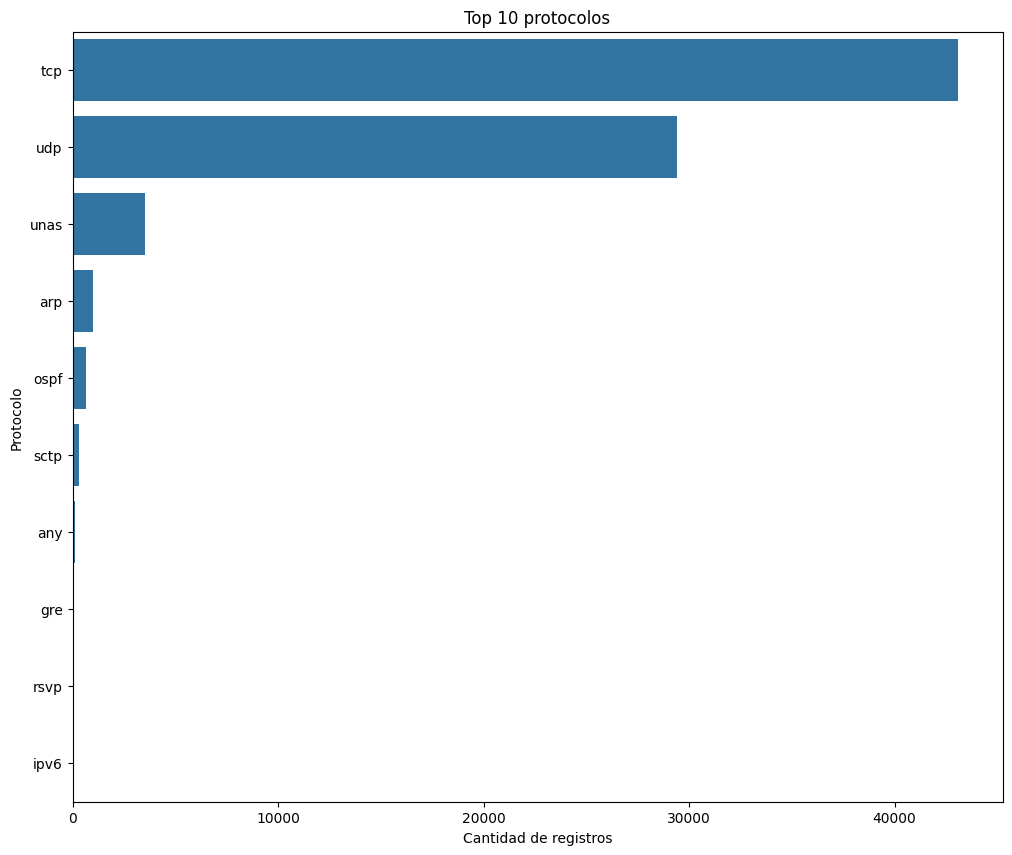

In [36]:
## Analisis univariado categoría proto
## al ser demasiados protocolos mostramos los 10 más frecuentes

top_protocolos = df["proto"].value_counts().head(10)

plt.figure(figsize=(12, 10))

sns.barplot(
    x=top_protocolos.values,
    y=top_protocolos.index
)

plt.title("Top 10 protocolos")
plt.xlabel("Cantidad de registros")
plt.ylabel("Protocolo")

plt.show()

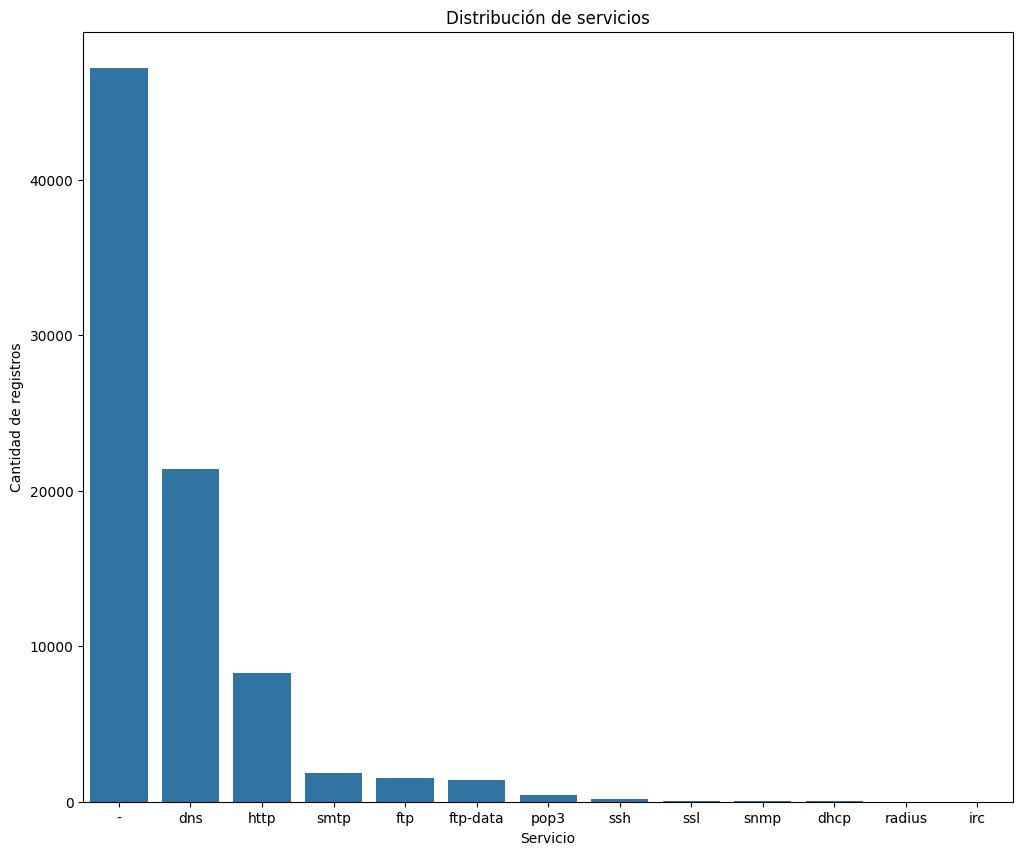

In [37]:
##Categoría service

plt.figure(figsize=(12, 10))

sns.countplot(
    x="service",
    data=df,
    order=df["service"].value_counts().index
)

plt.title("Distribución de servicios")
plt.xlabel("Servicio")
plt.ylabel("Cantidad de registros")

plt.show()

# Analisis Bivariado


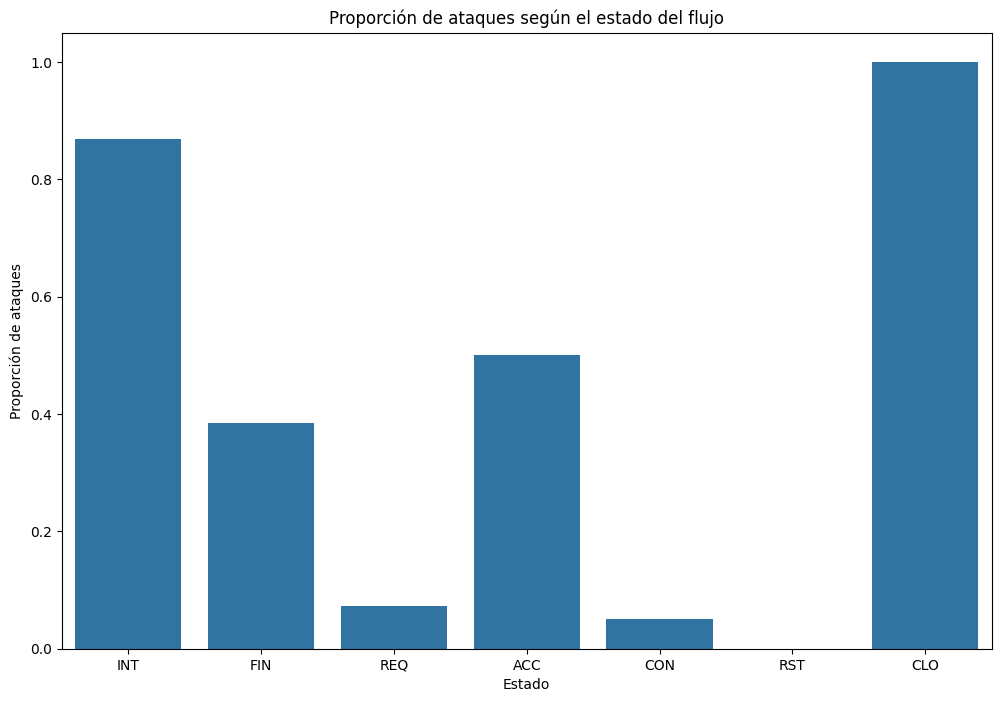

In [38]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x="state",
    y="label",
    data=df,
    errorbar=None
)

plt.title("Proporción de ataques según el estado del flujo")
plt.xlabel("Estado")
plt.ylabel("Proporción de ataques")

plt.show()


##state representa el estado observado del flujo/conexión

###FIN → flujo/conexión finalizada.
##CON → conexión establecida.
##REQ → solicitud o intento de conexión.
##RST → conexión reseteada.
##CLO → conexión cerrada.
##ACC → conexión aceptada.
##INT → estado interno/interrumpido según la codificación de Argus usada en el dataset.




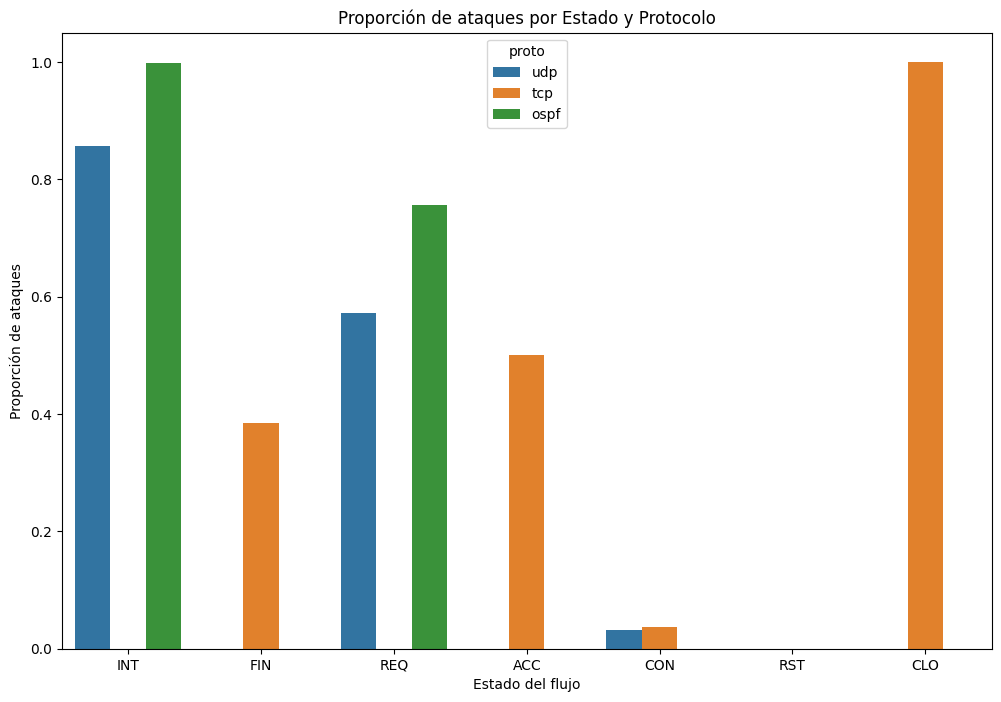

In [39]:
plt.figure(figsize=(12, 8))

sns.barplot(
    x="state",
    y="label",
    hue="proto",
    data=df[df["proto"].isin(["tcp", "udp", "ospf"])],
    errorbar=None
)

plt.title("Proporción de ataques por Estado y Protocolo")
plt.xlabel("Estado del flujo")
plt.ylabel("Proporción de ataques")

plt.show()


## relación de variable state y proto (udp, tcp.osfp)
## se tomaron solo los 3 protocolos con mayor cantidad de registros para que pueda entenderse mejor.

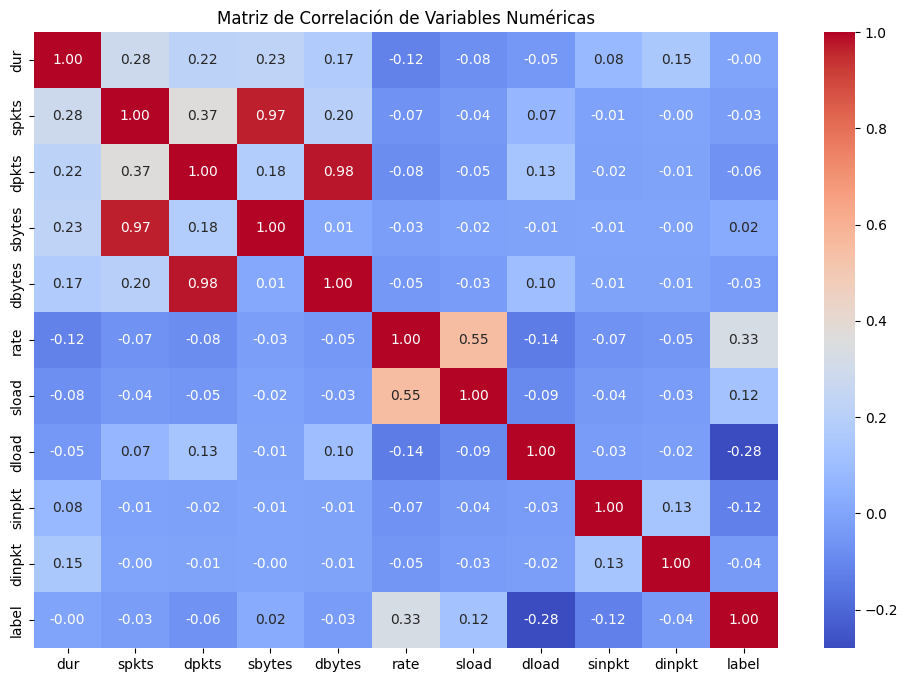

In [40]:
## Matriz de correlación

##+1   relación positiva perfecta
## 0   poca o ninguna relación lineal
## -1   relación negativa perfecta


## te tomaron solo algunas categorías numericas para esta matriz



variables = [
    "dur",
    "spkts",
    "dpkts",
    "sbytes",
    "dbytes",
    "rate",
    "sload",
    "dload",
    "sinpkt",
    "dinpkt",
    "label"
]

corr = df[variables].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Matriz de Correlación de Variables Numéricas")
plt.show()

# Análisis de outliers

En esta sección se compara el comportamiento de las variables **Send** y **Delivered** para evaluar qué tan similares son. El objetivo es decidir si se pueden combinar en una sola variable o si conviene mantenerlas separadas en el dataset.

In [41]:
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = serie[(serie < limite_inferior) | (serie > limite_superior)]
    return outliers, limite_inferior, limite_superior

def analizar_par(df, col_a, col_b, titulo_a=None, titulo_b=None):
    titulo_a = titulo_a or col_a
    titulo_b = titulo_b or col_b

    # Resumen numérico
    for col in (col_a, col_b):
        outliers, li, ls = detectar_outliers_iqr(df[col])
        print(f"--- {col.upper()} ---")
        print(f"Límite inferior: {li:.2f} | Límite superior: {ls:.2f}")
        print(f"Cantidad de outliers: {len(outliers)} ({len(outliers)/len(df)*100:.1f}% del total)\n")

    # Visualización comparativa
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=df[col_a], ax=axes[0], color="lightcoral")
    axes[0].set_title(f"Outliers en {titulo_a}")
    sns.boxplot(x=df[col_b], ax=axes[1], color="lightgreen")
    axes[1].set_title(f"Outliers en {titulo_b}")
    plt.tight_layout()
    plt.show()

--- SLOAD ---
Límite inferior: -97686277.83 | Límite superior: 162840336.30
Cantidad de outliers: 6715 (8.2% del total)

--- DLOAD ---
Límite inferior: -23787.12 | Límite superior: 39645.21
Cantidad de outliers: 18112 (22.0% del total)



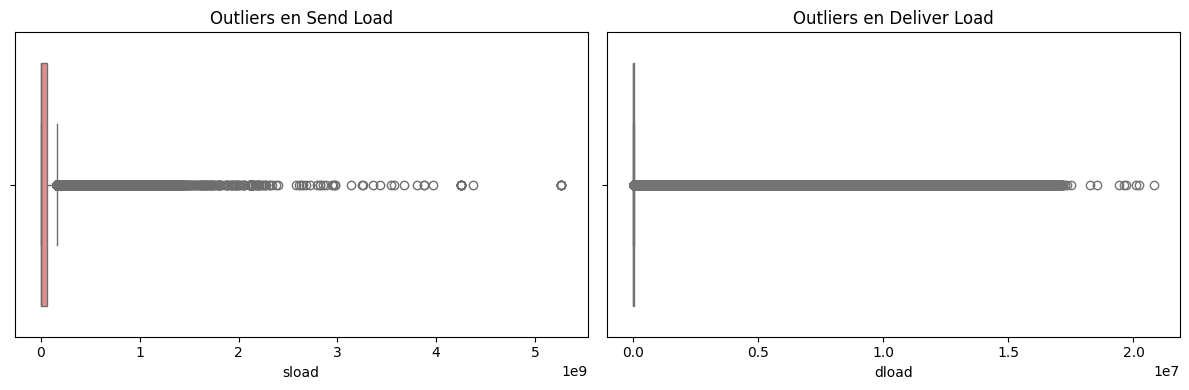

--- SPKTS ---
Límite inferior: -13.00 | Límite superior: 27.00
Cantidad de outliers: 10196 (12.4% del total)

--- DPKTS ---
Límite inferior: -15.00 | Límite superior: 25.00
Cantidad de outliers: 8907 (10.8% del total)



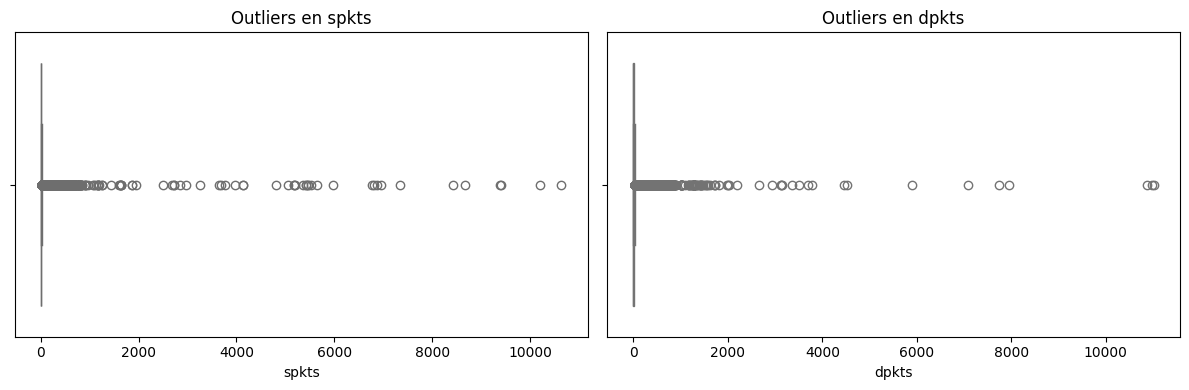

--- SBYTES ---
Límite inferior: -1635.00 | Límite superior: 3029.00
Cantidad de outliers: 9270 (11.3% del total)

--- DBYTES ---
Límite inferior: -1434.00 | Límite superior: 2390.00
Cantidad de outliers: 12308 (14.9% del total)



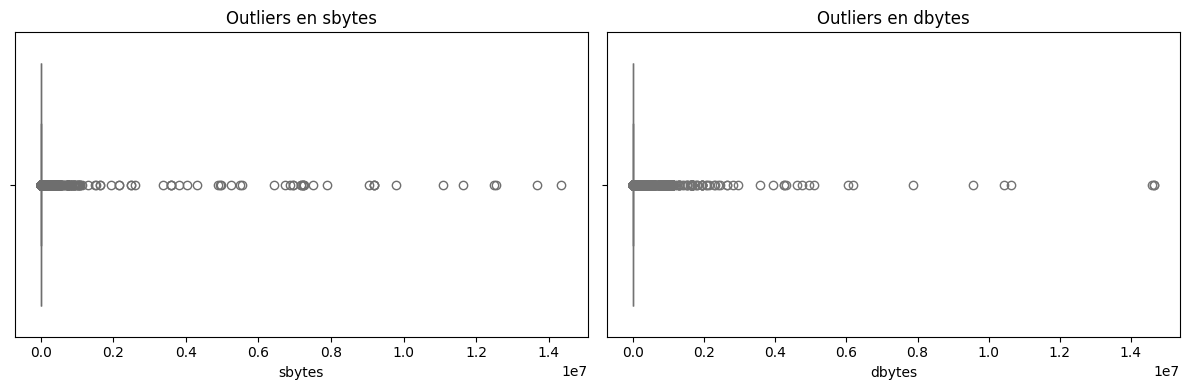

--- STTL ---
Límite inferior: -226.00 | Límite superior: 542.00
Cantidad de outliers: 0 (0.0% del total)

--- DTTL ---
Límite inferior: -378.00 | Límite superior: 630.00
Cantidad de outliers: 0 (0.0% del total)



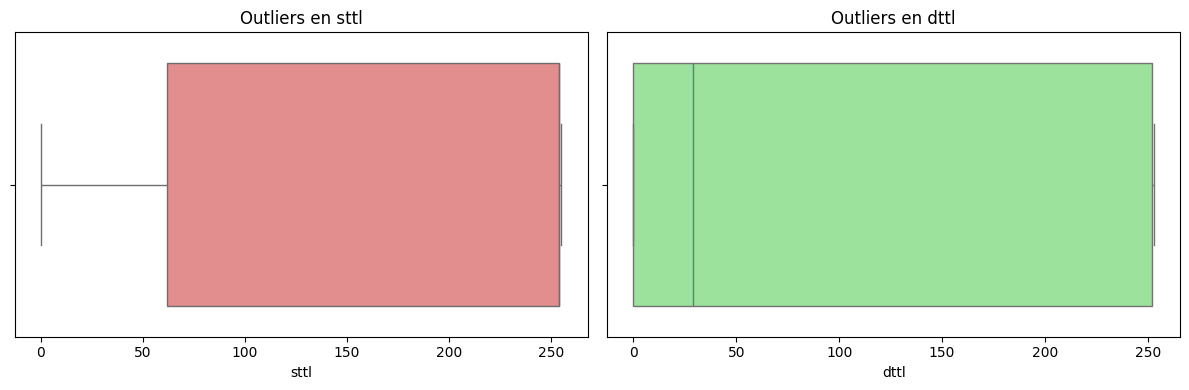

--- SLOSS ---
Límite inferior: -4.50 | Límite superior: 7.50
Cantidad de outliers: 5499 (6.7% del total)

--- DLOSS ---
Límite inferior: -3.00 | Límite superior: 5.00
Cantidad de outliers: 11272 (13.7% del total)



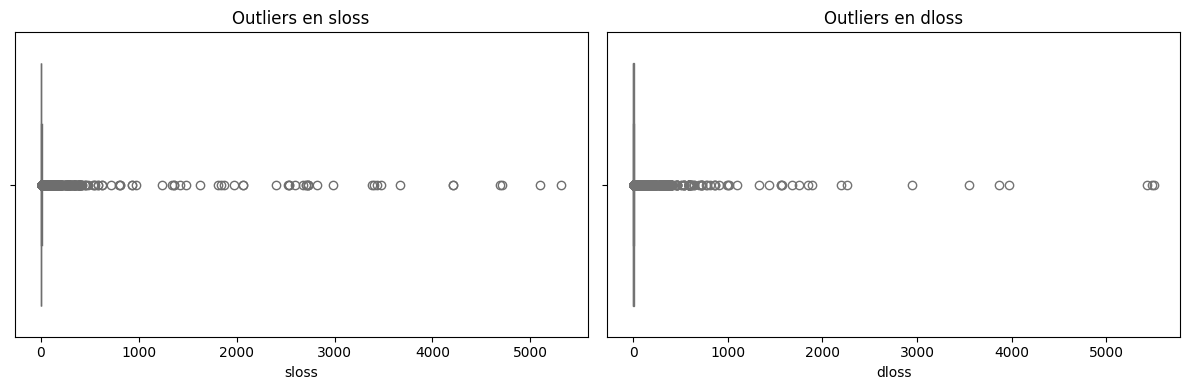

--- SINPKT ---
Límite inferior: -95.09 | Límite superior: 158.51
Cantidad de outliers: 5668 (6.9% del total)

--- DINPKT ---
Límite inferior: -94.70 | Límite superior: 157.84
Cantidad de outliers: 4717 (5.7% del total)



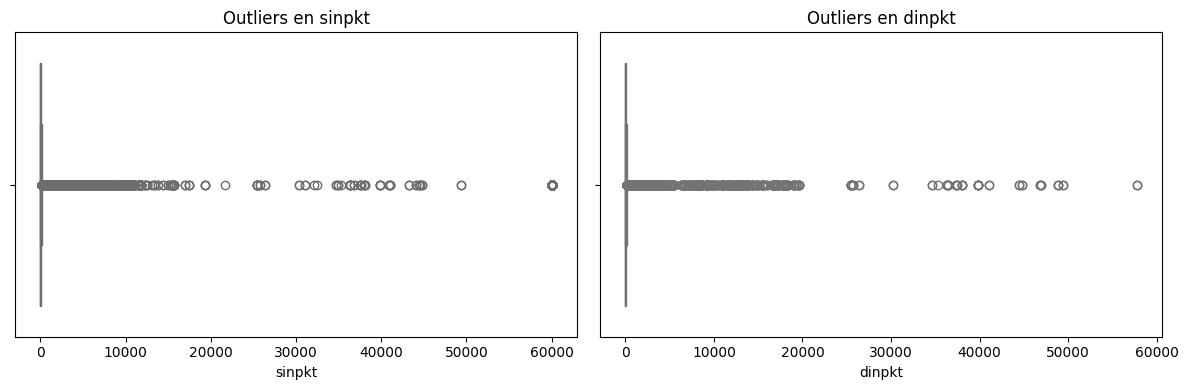

--- SJIT ---
Límite inferior: -4829.00 | Límite superior: 8048.33
Cantidad de outliers: 6321 (7.7% del total)

--- DJIT ---
Límite inferior: -192.69 | Límite superior: 321.15
Cantidad de outliers: 8573 (10.4% del total)



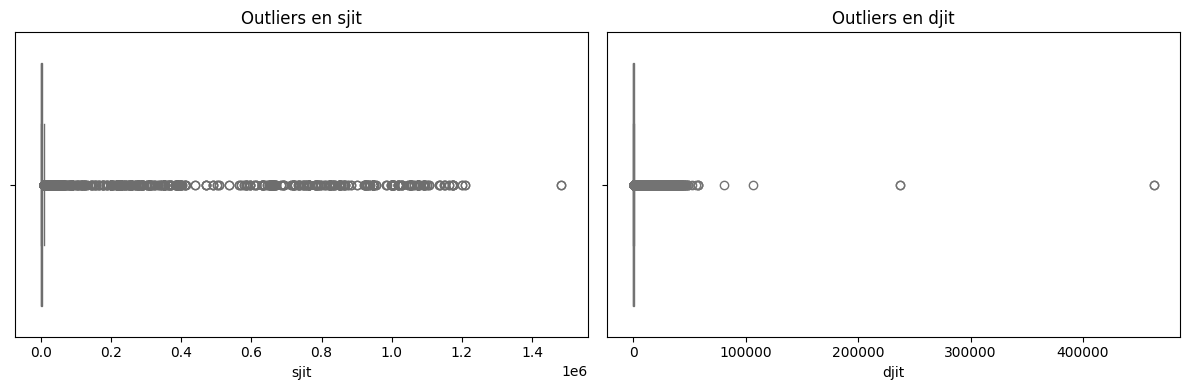

--- STCPB ---
Límite inferior: -3256964409.75 | Límite superior: 5428274016.25
Cantidad de outliers: 0 (0.0% del total)

--- DTCPB ---
Límite inferior: -3216307759.50 | Límite superior: 5360512932.50
Cantidad de outliers: 0 (0.0% del total)



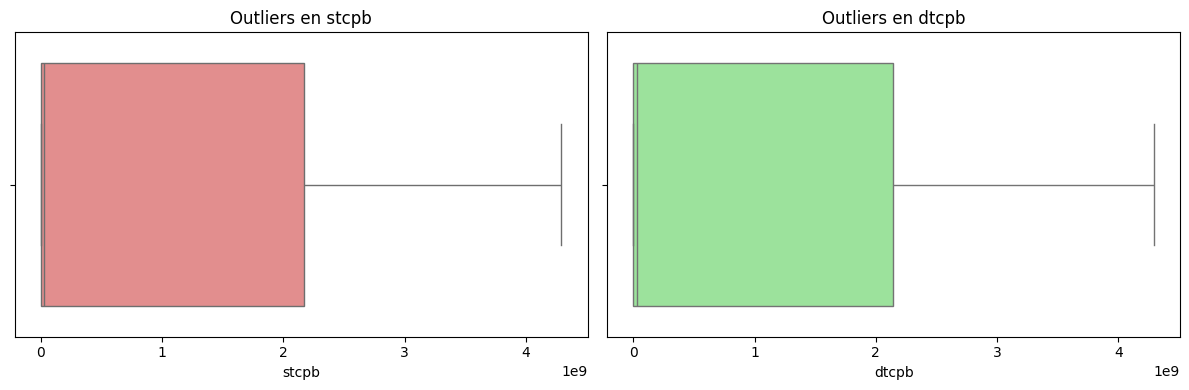

--- DWIN ---
Límite inferior: -382.50 | Límite superior: 637.50
Cantidad de outliers: 0 (0.0% del total)

--- SWIN ---
Límite inferior: -382.50 | Límite superior: 637.50
Cantidad de outliers: 0 (0.0% del total)



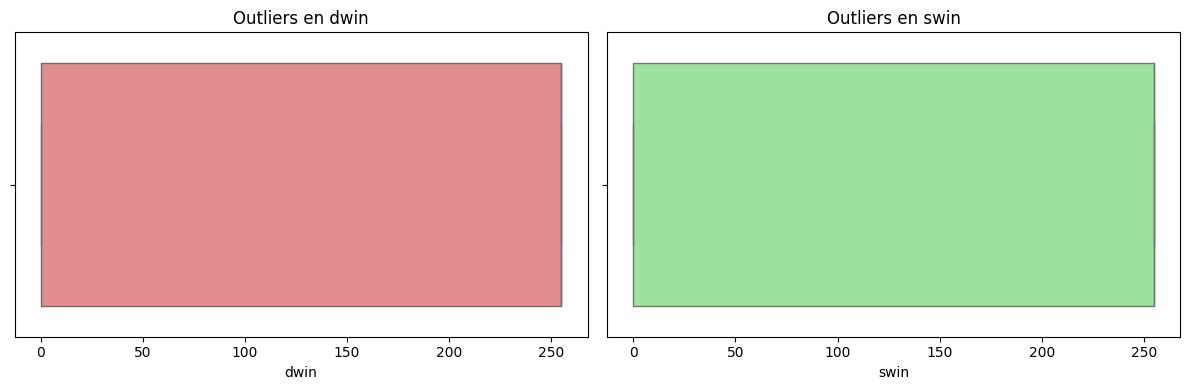

--- SMEAN ---
Límite inferior: -7.50 | Límite superior: 164.50
Cantidad de outliers: 11928 (14.5% del total)

--- DMEAN ---
Límite inferior: -130.50 | Límite superior: 217.50
Cantidad de outliers: 9902 (12.0% del total)



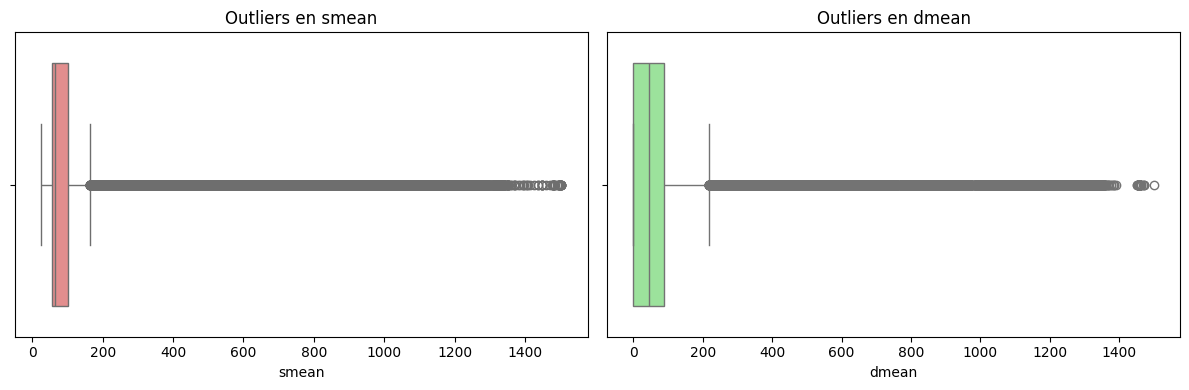

In [42]:
pares = [
    ("sload", "dload", "Send Load", "Deliver Load"),
    ("spkts", "dpkts"),
    ("sbytes", "dbytes"),
    ("sttl", "dttl"),
    ("sloss", "dloss"),
    ("sinpkt", "dinpkt"),
    ("sjit", "djit"),
    ("stcpb", "dtcpb"),
    ("dwin", "swin"),
    ("smean","dmean")
]

for par in pares:
    analizar_par(df, *par)

In [43]:
# Comparar si swin y dwin son idénticos
coincidentes_win = (df['swin'] == df['dwin']).sum()
total_filas_win = len(df)

print(f"Total de filas: {total_filas_win}")
print(f"Filas donde swin == dwin: {coincidentes_win} ({coincidentes_win / total_filas_win * 100:.2f}%)")

# Mostrar algunos ejemplos del tráfico TCP
trafico_tcp_win = df[df['proto'] == 'tcp']
print(f"\nFilas de protocolo TCP: {len(trafico_tcp_win)}")
print(f"Ejemplos de valores de ventana TCP (swin y dwin):")
display(trafico_tcp_win[['proto', 'swin', 'dwin']].drop_duplicates().head(100))

Total de filas: 82332
Filas donde swin == dwin: 80646 (97.95%)

Filas de protocolo TCP: 43095
Ejemplos de valores de ventana TCP (swin y dwin):


,proto,swin,dwin
29,tcp,255,255
52,tcp,255,0
40550,tcp,156,255
41036,tcp,255,81
41149,tcp,255,160
41267,tcp,255,77
41298,tcp,255,171
41336,tcp,202,255
41361,tcp,255,137
41407,tcp,255,164


# MODELO NEURONAL PYTORCH


### 1. Preprocesamiento de Datos

In [53]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler, LabelEncoder

# 1. Preparar características (X) y etiquetas (y) usando todo el dataset
X_train = df.drop(columns=["attack_cat", "label"])
y_train = df["label"].values

# 2. Codificar variables categóricas
categorical_cols = X_train.select_dtypes(include=['object']).columns
for col in categorical_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])

# 3. Escalar todas las características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 4. Convertir a tensores de PyTorch
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

# 5. Crear DataLoader para el entrenamiento completo por lotes
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)

print(f"Conjunto de entrenamiento completo listo: {X_train_t.shape}")

Conjunto de entrenamiento completo listo: torch.Size([82332, 42])


### 2. Definición de la Arquitectura de la Red Neuronal

In [54]:
class AttackClassifier(nn.Module):
    def __init__(self, input_dim):
        super(AttackClassifier, self).__init__()
        # Definición de capas
        self.network = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1),
            nn.Sigmoid() # Para salida binaria de probabilidad
        )

    def forward(self, x):
        return self.network(x)

# Inicializar el modelo, función de pérdida y optimizador
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

model = AttackClassifier(X_train.shape[1]).to(device)
criterion = nn.BCELoss() # Binary Cross Entropy Loss
optimizer = optim.Adam(model.parameters(), lr=0.001)

Usando dispositivo: cpu


### 3. Entrenamiento del Modelo

In [55]:
epochs = 500

for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)

        # Forward pass
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)

        # Backward pass y optimización
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch_x.size(0)

    epoch_loss /= len(train_loader.dataset)

    # Mostrar el progreso cada 50 épocas o en la primera/última
    if (epoch + 1) % 50 == 0 or epoch == 0 or epoch == epochs - 1:
        print(f"epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")

epoch [1/500] - Loss: 0.3240
epoch [50/500] - Loss: 0.0970
epoch [100/500] - Loss: 0.0896
epoch [150/500] - Loss: 0.0871
epoch [200/500] - Loss: 0.0850
epoch [250/500] - Loss: 0.0843
epoch [300/500] - Loss: 0.0829
epoch [350/500] - Loss: 0.0818
epoch [400/500] - Loss: 0.0811
epoch [450/500] - Loss: 0.0803
epoch [500/500] - Loss: 0.0807


### 4. Evaluación del Modelo

In [56]:
from sklearn.metrics import classification_report, accuracy_score
import pandas as pd
import numpy as np
import torch

# 1. Cargar el dataset de pruebas independiente
df_test = pd.read_csv(path + "/UNSW_NB15_testing-set.csv")

# 2. Separar características y etiquetas de prueba
X_test = df_test.drop(columns=["id", "attack_cat", "label"])
y_test = df_test["label"].values

# 3. Aplicar codificación categórica segura (manejando etiquetas no vistas)
for col in X_test.select_dtypes(include=['object']).columns:
    # Obtener categorías del conjunto de entrenamiento
    train_categories = df[col].unique()
    category_to_index = {category: idx for idx, category in enumerate(train_categories)}

    # Mapear las categorías conocidas, y usar un índice especial (len(train_categories)) para las no vistas
    unknown_index = len(train_categories)
    X_test[col] = X_test[col].map(lambda x: category_to_index.get(x, unknown_index))

# 4. Escalar usando el mismo scaler ajustado con los datos de entrenamiento
X_test_scaled = scaler.transform(X_test)

# 5. Convertir a tensor de PyTorch
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)

# 6. Evaluar el modelo
model.eval()
with torch.no_grad():
    y_pred_probs = model(X_test_t).cpu().numpy()
    y_pred = (y_pred_probs >= 0.5).astype(int)

print("\n--- REPORTE DE CLASIFICACIÓN EN EL DATASET DE PRUEBA INDEPENDIENTE ---")
print(classification_report(y_test, y_pred, target_names=["Normal", "Ataque"]))

accuracy = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy) Final: {accuracy * 100:.2f}%")


--- REPORTE DE CLASIFICACIÓN EN EL DATASET DE PRUEBA INDEPENDIENTE ---
              precision    recall  f1-score   support

      Normal       0.98      0.77      0.86     56000
      Ataque       0.90      0.99      0.94    119341

    accuracy                           0.92    175341
   macro avg       0.94      0.88      0.90    175341
weighted avg       0.92      0.92      0.92    175341

Exactitud (Accuracy) Final: 91.90%
